# Tuần 2 – Đặc trưng thống nhất · 4 baseline · Mô hình riêng **GA-DCR** · Phân cụm động K-means++ × GA · *Ưu tiên Recall và F2*
**Đề tài NCKH SV – ĐH Phenikaa:** Cảnh báo sớm sinh viên có nguy cơ học tập kém bằng AI · Dữ liệu: **OULAD** và **UCI 697**

| # | Yêu cầu tuần 2 | Phần |
|---|---|---|
| 1 | Chỉ số: **Recall và F2 là chính**, Precision là ràng buộc ổn định; cảnh báo top-q% | §1 |
| 2 | Thống nhất bộ đặc trưng cho 2 bộ dữ liệu, bổ sung đặc trưng mới từ kết quả tuần 1 | §2–§3 |
| 3 | 4 baseline **khác bài báo tham khảo:** Logistic Regression, Decision Tree, Random Forest, XGBoost | §5 |
| 4 | **Phân cụm động:** K-means++ có GA tối ưu, sinh ra các mức cảnh báo theo dữ liệu và theo thời gian | §4 |
| 5 | **Mô hình riêng GA-DCR**: tổ hợp có trọng số (tổng hệ số = 1) do GA huấn luyện, so với 4 baseline | §5–§6 |
| 6 | Điểm mới so với bài báo tham khảo (Wang, *Sci. Reports* 15:35122, 2025) | §7 |

> Đặt notebook trong cùng thư mục với `oulad/` và `uci_697/` (giống tuần 1). Thời gian chạy khoảng 5–7 phút. Kết quả được ghi vào `week2_outputs/`.

## §1. Chỉ số đánh giá và quy tắc cảnh báo
**Bản chất trong bài toán cảnh báo học vụ:**
- **Recall** = TP/(TP+FN): trong số SV *thực sự* sẽ trượt hoặc bỏ học, hệ thống **phát hiện được bao nhiêu**. Bỏ sót (FN) là sai lầm **không sửa lại được**.
- **Precision** = TP/(TP+FP): trong danh sách đưa cho cố vấn, bao nhiêu SV **thực sự cần giúp**. Báo nhầm quá nhiều sẽ làm cố vấn quá tải và mất niềm tin.
- **F2** = $5PR/(4P+R)$ coi **Recall nặng gấp đôi Precision**.

| Vai trò | Chỉ số |
|---|---|
| **Chỉ số chính** | **Recall, F2** |
| **Ràng buộc ổn định** | Precision ≥ $P_{min}$; số SV bị cảnh báo ≤ 50% |
| Bổ trợ | PR-AUC (chất lượng xếp hạng SV) |

**Quy tắc cảnh báo theo năng lực tư vấn (top-q%).** Mỗi mô hình cho một điểm rủi ro. Hệ thống **cảnh báo q% SV có điểm cao nhất** trong khóa, với q được chọn trên OOF của tập train:
$$q^*=\arg\max_{q\le 50\%} F_2(q)\quad\text{s.t.}\quad \text{Precision}(q)\ \ge\ P_{min}=\max\!\big(0{,}5;\ \bar y_{train}+0{,}15\big)$$

Vì sao chọn theo tỷ lệ SV thay vì ngưỡng xác suất cố định?
1. **Sát vận hành:** khoa quyết định "mỗi kỳ cố vấn gặp tối đa q% SV".
2. **Bền với thay đổi giữa các khóa:** tỷ lệ nguy cơ OULAD đổi từ 44% (2013) xuống 42% (2014), làm ngưỡng xác suất học từ khóa cũ bị lệch. Thứ tự xếp hạng thì ổn định hơn.
3. **So sánh công bằng:** các mô hình được so khi cùng số SV phải gặp, nên mô hình nào **xếp hạng tốt hơn** thì thắng đồng thời cả Recall, F2 và Precision.

Cả 5 mô hình (4 baseline và GA-DCR) dùng **cùng quy tắc** này.

## §0. Cấu hình và nạp dữ liệu

In [1]:
%matplotlib inline
import os
os.environ["PYTHONWARNINGS"] = "ignore"          # tắt cảnh báo của các tiến trình con (joblib/loky)
import re, json, time, warnings, gc
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, silhouette_score, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, train_test_split
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("⚠ Chưa cài xgboost → dùng HistGradientBoosting thay thế (pip install xgboost để đúng yêu cầu)")

OULAD_DIR = None      # để None => tự dò; hoặc r"C:\...\oulad"
UCI697_FILE = None    # để None => tự dò; hoặc r"C:\...\uci_697\data.csv"
BASE = Path.cwd(); OUT = BASE / "week2_outputs"; FIG = OUT / "figures"; TAB = OUT / "tables"
for p in (FIG, TAB): p.mkdir(parents=True, exist_ok=True)
SEED = 42; rng_global = np.random.default_rng(SEED)

def _roots(): return [BASE, BASE.parent, BASE.parent.parent]
def find_oulad_dir():
    for root in _roots():
        for d in [root / "oulad"] + sorted(p for p in root.glob("*oulad*") if p.is_dir()):
            if d.is_dir():
                hit = next(d.rglob("studentInfo.csv"), None)
                if hit is not None: return hit.parent
    raise FileNotFoundError("Không tìm thấy studentInfo.csv – điền OULAD_DIR")
def find_uci697_file():
    for root in _roots():
        for d in [root / "uci_697"] + sorted(p for p in root.glob("*697*") if p.is_dir()):
            if d.is_dir():
                for f in sorted(d.rglob("*.csv")):
                    h = f.read_text(encoding="utf-8-sig", errors="ignore")[:4000]
                    if "Target" in h and "Curricular units" in h: return f
    raise FileNotFoundError("Không tìm thấy CSV UCI 697 – điền UCI697_FILE")
OULAD_DIR = Path(OULAD_DIR) if OULAD_DIR else find_oulad_dir()
UCI697_FILE = Path(UCI697_FILE) if UCI697_FILE else find_uci697_file()
print("OULAD:", OULAD_DIR, "\nUCI 697:", UCI697_FILE)

PAL = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
           green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
MODEL_COLORS = {"LogReg": PAL["blue"], "DecisionTree": PAL["orange"], "RandomForest": PAL["aqua"],
                "XGBoost": PAL["yellow"], "GA-DCR (đề xuất)": PAL["violet"], "(tham chiếu) Cảnh báo tất cả": MUTED}
LEVEL_COLORS = {"Xanh": "#1baf7a", "Vàng": "#eda100", "Cam": "#ec835a", "Đỏ": "#d03b3b"}
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 100, "savefig.dpi": 150,
    "savefig.bbox": "tight"})
def save_show(fig, name): fig.savefig(FIG / name); plt.show()
def save_tab(df, name, index=False): df.to_csv(TAB / name, index=index, encoding="utf-8-sig"); return df

OULAD: /home/claude/nb3/oulad 
UCI 697: /home/claude/nb3/uci_697/data.csv


In [2]:
t0 = time.time(); NA = ["?", ""]
O = {k: pd.read_csv(OULAD_DIR / f"{k}.csv", na_values=NA) for k in
     ["courses", "assessments", "vle", "studentInfo", "studentRegistration", "studentAssessment"]}
O["studentVle"] = pd.read_csv(OULAD_DIR / "studentVle.csv", dtype={"code_module": "category",
                  "code_presentation": "category", "id_student": "int32", "id_site": "int32", "date": "int16", "sum_click": "int32"})
head = UCI697_FILE.read_text(encoding="utf-8-sig", errors="ignore")[:4000]
uci = pd.read_csv(UCI697_FILE, sep=";" if head.count(";") > head.count(",") else ",", encoding="utf-8-sig")
uci.columns = [re.sub(r"\s+", " ", c).strip() for c in uci.columns]
uci = uci.rename(columns={"Nacionality": "Nationality"}); uci["Target"] = uci.Target.astype(str).str.strip()
print(f"Nạp xong {time.time()-t0:.0f}s | OULAD studentVle = {len(O['studentVle']):,} dòng | UCI 697 = {uci.shape}")

Nạp xong 4s | OULAD studentVle = 10,655,280 dòng | UCI 697 = (4424, 37)


---
## §2. Xây dựng đặc trưng (gồm đặc trưng mới rút ra từ kết quả tuần 1)
### 2.1 OULAD – đặc trưng tại mốc ngày t, chống rò rỉ dữ liệu
Tuần 1 cho thấy 3 điều:
1. Hành vi trên LMS **so với bạn cùng lớp** mạnh hơn số click tuyệt đối.
2. **Tín hiệu suy giảm gần đây** (lâu không đăng nhập, nhiều tuần không hoạt động) làm tăng nguy cơ.
3. **Kỷ luật nộp bài** (bỏ lỡ hạn, nộp sát hạn) là tín hiệu mạnh.

Vì vậy tuần 2 bổ sung các đặc trưng mới (★), nhất là nhóm *động/xu hướng*.

In [3]:
ENR = ["code_module", "code_presentation", "id_student"]; CRS = ["code_module", "code_presentation"]
EDU = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2, "HE Qualification": 3, "Post Graduate Qualification": 4}
IMD = {f"{i*10}-{i*10+10}%": i for i in range(10)} | {"10-20": 1}
AGE = {"0-35": 0, "35-55": 1, "55<=": 2}
base_o = O["studentInfo"].merge(O["studentRegistration"], on=ENR)
base_o["at_risk"] = base_o.final_result.isin(["Fail", "Withdrawn"]).astype(int)
base_o["year"] = base_o.code_presentation.str[:4].astype(int)
base_o["edu_ord"] = base_o.highest_education.map(EDU); base_o["imd_ord"] = base_o.imd_band.map(IMD)
base_o["age_ord"] = base_o.age_band.map(AGE)
base_o["gender_M"] = (base_o.gender == "M").astype(int); base_o["disability_Y"] = (base_o.disability == "Y").astype(int)

sv = O["studentVle"].merge(O["vle"][["id_site", "activity_type"]], on="id_site")
for k in CRS: sv[k] = sv[k].astype(str)
daily = sv.groupby(ENR + ["date", "activity_type"]).sum_click.sum().rename("clicks").reset_index()
del sv; gc.collect()
A = O["assessments"]; A = A[A.assessment_type != "Exam"]
SA = O["studentAssessment"].merge(A, on="id_assessment"); SA = SA[SA.is_banked == 0]

def oulad_features(t):
    X = base_o[base_o.date_unregistration.isna() | (base_o.date_unregistration >= t)].copy()
    dv = daily[daily.date < t]; g = dv.groupby(ENR)
    f = pd.DataFrame({"clicks_total": g.clicks.sum(), "active_days": g.date.nunique(), "last_day": g.date.max(),
                      "activity_diversity": g.activity_type.nunique(),                                   # ★
                      "clicks_prestart": dv[dv.date < 0].groupby(ENR).clicks.sum(),
                      "clk_forum": dv[dv.activity_type == "forumng"].groupby(ENR).clicks.sum(),
                      "clk_quiz": dv[dv.activity_type == "quiz"].groupby(ENR).clicks.sum()})
    rec = dv[dv.date >= t - 14].groupby(ENR)
    f["clicks_last14"] = rec.clicks.sum(); f["active_days_last14"] = rec.date.nunique()
    nw = max(1, int(np.ceil(t / 7)))
    wk = dv[dv.date >= 0].assign(w=lambda x: x.date // 7).groupby(ENR + ["w"]).clicks.sum().unstack(fill_value=0)
    wk = wk.reindex(columns=range(nw), fill_value=0)
    xs = np.arange(nw) - (nw - 1) / 2
    f = f.join(pd.DataFrame({
        "clicks_week_slope": (np.log1p(wk.values) @ xs / max(1e-9, xs @ xs)) if nw > 1 else 0.0,          # ★ xu hướng
        "weeks_inactive": (wk.values == 0).sum(1),                                                       # ★
        "engagement_cv": wk.std(1).values / (wk.mean(1).values + 1)}, index=wk.index))                     # ★ đều đặn
    X = X.merge(f.reset_index(), on=ENR, how="left")
    for c in ["clicks_total", "active_days", "activity_diversity", "clicks_prestart", "clk_forum", "clk_quiz",
              "clicks_last14", "active_days_last14", "clicks_week_slope", "engagement_cv"]:
        X[c] = X[c].fillna(0)
    X["weeks_inactive"] = X.weeks_inactive.fillna(nw)
    X["days_since_last_active"] = (t - X.last_day).fillna(t + 30)                                         # ★
    X["clicks_pct_in_course"] = X.groupby(CRS).clicks_total.rank(pct=True)                                 # ★ tương đối
    X["active_pct_in_course"] = X.groupby(CRS).active_days.rank(pct=True)                                  # ★
    X["recent_share"] = X.clicks_last14 / (X.clicks_total + 1)                                             # ★
    X["forum_share"] = X.clk_forum / (X.clicks_total + 1); X["quiz_share"] = X.clk_quiz / (X.clicks_total + 1)  # ★
    s = SA[SA.date_submitted < t]; gs = s.groupby(ENR); key = [s[k] for k in ENR]
    fa = pd.DataFrame({"n_submitted": gs.size(), "mean_score": gs.score.mean(), "min_score": gs.score.min(),
                       "weighted_score": (s.score * s.weight).groupby(key).sum() / s.weight.groupby(key).sum().replace(0, np.nan),
                       "mean_days_early": (s.date - s.date_submitted).groupby(key).mean(),                 # ★ kỷ luật
                       "n_fail_assess": (s.score < 40).groupby(key).sum()})
    X = X.merge(fa.reset_index(), on=ENR, how="left")
    due = A[A.date < t].groupby(CRS).size().rename("n_due").reset_index()
    sub = s[s.date < t].groupby(ENR).size().rename("n_sub_due").reset_index()
    X = X.merge(due, on=CRS, how="left").merge(sub, on=ENR, how="left")
    X[["n_due", "n_sub_due", "n_submitted", "n_fail_assess"]] = X[["n_due", "n_sub_due", "n_submitted", "n_fail_assess"]].fillna(0)
    X["n_missed"] = (X.n_due - X.n_sub_due).clip(lower=0)                                                  # ★
    X["submit_rate"] = np.where(X.n_due > 0, X.n_sub_due / X.n_due.replace(0, 1), 1.0)
    X["score_rel_course"] = X.mean_score - X.groupby(CRS).mean_score.transform("median")                  # ★
    return X.drop(columns=["last_day", "clk_forum", "clk_quiz", "n_sub_due", "n_due"])

OULAD_GROUPS = {
    "G1 Nền tảng cá nhân": ["gender_M", "age_ord", "disability_Y", "imd_ord", "edu_ord"],
    "G2 Học vụ/hành chính": ["num_of_prev_attempts", "studied_credits", "date_registration", "code_module"],
    "G3 Kết quả quá trình": ["mean_score", "min_score", "weighted_score", "n_fail_assess", "score_rel_course"],
    "G4 Mức độ tham gia": ["clicks_total", "active_days", "clicks_pct_in_course", "active_pct_in_course",
                               "clicks_prestart", "activity_diversity", "forum_share", "quiz_share"],
    "G5 Kỷ luật & tài chính": ["n_submitted", "n_missed", "submit_rate", "mean_days_early"],
    "G6 Động/xu hướng": ["clicks_last14", "active_days_last14", "recent_share", "clicks_week_slope",
                         "weeks_inactive", "days_since_last_active", "engagement_cv"],
}
X28 = oulad_features(28)
print("OULAD ngày 28:", X28.shape, "| tỷ lệ nguy cơ", round(X28.at_risk.mean(), 3))

OULAD ngày 28: (27553, 45) | tỷ lệ nguy cơ 0.442


### 2.2 UCI 697 – đặc trưng theo 3 mốc: **lúc nhập học → sau HK1 → sau HK2**
Từ tuần 1 rút ra:
- Tỷ lệ qua môn và **tình trạng tài chính** là tín hiệu mạnh nhất.
- Các biến vĩ mô không có tác dụng, nên **loại bỏ**.
- Nghề nghiệp của bố mẹ có quá nhiều mã và tác dụng yếu, nên **loại bỏ**.

In [4]:
U = uci.copy(); U["at_risk"] = (U.Target == "Dropout").astype(int)
for s, tag in [("1st", "1"), ("2nd", "2")]:
    cu = lambda k: U[f"Curricular units {s} sem ({k})"]
    U[f"enrolled_{tag}"] = cu("enrolled"); U[f"approved_{tag}"] = cu("approved"); U[f"grade_{tag}"] = cu("grade")
    U[f"pass_ratio_{tag}"] = np.where(cu("enrolled") > 0, cu("approved") / cu("enrolled").replace(0, 1), np.nan)      # ★
    U[f"eval_per_unit_{tag}"] = np.where(cu("enrolled") > 0, cu("evaluations") / cu("enrolled").replace(0, 1), np.nan) # ★
    U[f"no_eval_ratio_{tag}"] = np.where(cu("enrolled") > 0, cu("without evaluations") / cu("enrolled").replace(0, 1), np.nan)  # ★
    U[f"credited_share_{tag}"] = cu("credited") / (cu("credited") + cu("enrolled") + 1)                   # ★
U["financial_risk_index"] = U.Debtor + (1 - U["Tuition fees up to date"]) + (1 - U["Scholarship holder"])   # ★ 0–3
U["admission_gap"] = U["Admission grade"] - U["Previous qualification (grade)"]                          # ★
U["grade_delta"] = U.grade_2 - U.grade_1                                                                  # ★ động
U["pass_ratio_delta"] = U.pass_ratio_2 - U.pass_ratio_1                                                   # ★ động
U["approved_delta"] = U.approved_2 - U.approved_1                                                         # ★ động

UCI_CAT = ["Application mode", "Course", "Previous qualification", "Marital status",
           "Mother's qualification", "Father's qualification"]
UCI_GROUPS = {
    "G1 Nền tảng cá nhân": ["Gender", "Age at enrollment", "Marital status", "International", "Displaced",
                            "Educational special needs", "Mother's qualification", "Father's qualification"],
    "G2 Học vụ/hành chính": ["Application mode", "Application order", "Course", "Daytime/evening attendance",
                             "Previous qualification", "Previous qualification (grade)", "Admission grade", "admission_gap"],
    "G3 Kết quả quá trình": ["approved_1", "grade_1", "pass_ratio_1", "approved_2", "grade_2", "pass_ratio_2"],
    "G4 Mức độ tham gia": ["enrolled_1", "eval_per_unit_1", "credited_share_1", "enrolled_2", "eval_per_unit_2", "credited_share_2"],
    "G5 Kỷ luật & tài chính": ["no_eval_ratio_1", "no_eval_ratio_2", "Debtor", "Tuition fees up to date",
                               "Scholarship holder", "financial_risk_index"],
    "G6 Động/xu hướng": ["grade_delta", "pass_ratio_delta", "approved_delta"],
}
UCI_STAGE = {"Nhập học": lambda c: not re.search(r"_(1|2)$|delta", c),
             "Sau HK1": lambda c: not re.search(r"_2$|delta", c),
             "Sau HK2": lambda c: True}
DROPPED_UCI = ["Unemployment rate", "Inflation rate", "GDP", "Nationality", "Mother's occupation", "Father's occupation"]
print("UCI 697:", U.shape, "| tỷ lệ Dropout", round(U.at_risk.mean(), 3))

UCI 697: (4424, 57) | tỷ lệ Dropout 0.321


---
## §3. Thống nhất bộ đặc trưng cho 2 bộ dữ liệu
Cả hai bộ được quy về **cùng một khung 6 nhóm đặc trưng** (G1–G6), để mô hình và hệ thống cảnh báo dùng chung một cách diễn giải. Quy trình chọn lọc có 2 bước, chỉ thực hiện **trên tập train**:
1. **Lọc theo tri thức** từ tuần 1: bỏ biến vĩ mô, biến trùng nghĩa, biến có quá nhiều mã mà tác dụng yếu.
2. **Lọc tương quan:** cặp đặc trưng nào có |Spearman ρ| > 0,85 thì giữ đặc trưng có |ρ| với nhãn cao hơn. Ngưỡng 0,85 giống bài báo tham khảo, nhưng ở đây dùng Spearman vì nhiều biến lệch phân phối.

In [5]:
def corr_filter(df, feats, y, thr=0.85):
    num = [c for c in feats if pd.api.types.is_numeric_dtype(df[c])]
    cm = df[num].corr(method="spearman").abs()
    rel = df[num].corrwith(pd.Series(y, index=df.index), method="spearman").abs()
    drop, log = set(), []
    for i, a in enumerate(num):
        for b in num[i + 1:]:
            if a in drop or b in drop: continue
            if cm.loc[a, b] > thr:
                lose = a if rel[a] < rel[b] else b; keep = b if lose == a else a
                drop.add(lose); log.append((lose, keep, round(cm.loc[a, b], 3)))
    return [c for c in feats if c not in drop], log

# Chia dữ liệu: OULAD theo thời gian (2013 → 2014) và loại SV đã xuất hiện ở train khỏi test (tránh rò rỉ theo SV)
tr_o = X28[X28.year == 2013]; te_o = X28[(X28.year == 2014) & (~X28.id_student.isin(tr_o.id_student))]
print(f"OULAD: train 2013 = {len(tr_o):,} | test 2014 = {len(te_o):,} (đã loại {((X28.year==2014)&X28.id_student.isin(tr_o.id_student)).sum():,} lượt của SV có ở train)")
idx_tr_u, idx_te_u = train_test_split(U.index, test_size=0.2, stratify=U.at_risk, random_state=SEED)
print(f"UCI 697: train = {len(idx_tr_u):,} | test = {len(idx_te_u):,} (80/20 phân tầng)")

all_o = sum(OULAD_GROUPS.values(), [])
FEAT_O, drop_o = corr_filter(tr_o, all_o, tr_o.at_risk.values)
all_u = sum(UCI_GROUPS.values(), [])
FEAT_U, drop_u = {}, {}
for st, f in UCI_STAGE.items():   # lọc tương quan RIÊNG từng mốc: mốc sớm không được "mượn" đặc trưng của mốc sau
    FEAT_U[st], drop_u[st] = corr_filter(U.loc[idx_tr_u], [c for c in all_u if f(c)], U.loc[idx_tr_u, "at_risk"].values)
FEAT_U_ALL = FEAT_U["Sau HK2"]

rows = []
for g in OULAD_GROUPS:
    rows.append(dict(nhom=g, OULAD_ung_vien=len(OULAD_GROUPS[g]), OULAD_giu=sum(c in FEAT_O for c in OULAD_GROUPS[g]),
                     UCI_ung_vien=len(UCI_GROUPS[g]), UCI_nhap_hoc=sum(c in FEAT_U["Nhập học"] for c in UCI_GROUPS[g]),
                     UCI_sau_HK1=sum(c in FEAT_U["Sau HK1"] for c in UCI_GROUPS[g]), UCI_sau_HK2=sum(c in FEAT_U["Sau HK2"] for c in UCI_GROUPS[g]),
                     OULAD_dac_trung=", ".join(c for c in OULAD_GROUPS[g] if c in FEAT_O),
                     UCI_dac_trung_sau_HK2=", ".join(c for c in UCI_GROUPS[g] if c in FEAT_U_ALL)))
feat_table = pd.DataFrame(rows)
numcols = ["OULAD_ung_vien", "OULAD_giu", "UCI_ung_vien", "UCI_nhap_hoc", "UCI_sau_HK1", "UCI_sau_HK2"]
feat_table = feat_table[["nhom"] + numcols + ["OULAD_dac_trung", "UCI_dac_trung_sau_HK2"]]
feat_table.loc[len(feat_table)] = ["TỔNG", *feat_table[numcols].sum().values, "", ""]
save_tab(feat_table, "03_unified_feature_set.csv")
display(feat_table)
print("Loại do tương quan cao (bị loại, giữ lại, |ρ|):")
print("  OULAD :", drop_o); print("  UCI   :", drop_u)
print("  UCI loại theo tri thức tuần 1:", DROPPED_UCI)
print("OULAD dùng", len(FEAT_O), "đặc trưng |", {st: len(v) for st, v in FEAT_U.items()}, "← số đặc trưng UCI theo mốc")

OULAD: train 2013 = 11,818 | test 2014 = 14,269 (đã loại 1,466 lượt của SV có ở train)
UCI 697: train = 3,539 | test = 885 (80/20 phân tầng)


,nhom,OULAD_ung_vien,OULAD_giu,UCI_ung_vien,UCI_nhap_hoc,UCI_sau_HK1,UCI_sau_HK2,OULAD_dac_trung,UCI_dac_trung_sau_HK2
0,G1 Nền tảng cá nhân,5,5,8,8,8,8,"gender_M, age_ord, disability_Y, imd_ord, edu_ord","Gender, Age at enrollment, Marital status, Int..."
1,G2 Học vụ/hành chính,4,4,8,8,8,8,"num_of_prev_attempts, studied_credits, date_re...","Application mode, Application order, Course, D..."
2,G3 Kết quả quá trình,5,2,6,0,3,5,"n_fail_assess, score_rel_course","grade_1, pass_ratio_1, approved_2, grade_2, pa..."
3,G4 Mức độ tham gia,8,5,6,0,3,4,"active_pct_in_course, clicks_prestart, activit...","eval_per_unit_1, enrolled_2, eval_per_unit_2, ..."
4,G5 Kỷ luật & tài chính,4,3,6,4,5,6,"n_submitted, n_missed, mean_days_early","no_eval_ratio_1, no_eval_ratio_2, Debtor, Tuit..."
5,G6 Động/xu hướng,7,6,3,0,0,2,"active_days_last14, recent_share, clicks_week_...","grade_delta, pass_ratio_delta"
6,TỔNG,33,25,37,20,27,33,,


Loại do tương quan cao (bị loại, giữ lại, |ρ|):
  OULAD : [('min_score', 'mean_score', np.float64(0.975)), ('weighted_score', 'mean_score', np.float64(0.976)), ('mean_score', 'score_rel_course', np.float64(0.925)), ('clicks_total', 'active_days', np.float64(0.894)), ('active_days', 'active_pct_in_course', np.float64(0.882)), ('clicks_pct_in_course', 'active_pct_in_course', np.float64(0.889)), ('submit_rate', 'n_missed', np.float64(0.999)), ('clicks_last14', 'active_days_last14', np.float64(0.861))]
  UCI   : {'Nhập học': [], 'Sau HK1': [], 'Sau HK2': [('approved_1', 'approved_2', np.float64(0.887)), ('enrolled_1', 'enrolled_2', np.float64(0.96)), ('credited_share_1', 'credited_share_2', np.float64(0.91)), ('approved_delta', 'pass_ratio_delta', np.float64(0.858))]}
  UCI loại theo tri thức tuần 1: ['Unemployment rate', 'Inflation rate', 'GDP', 'Nationality', "Mother's occupation", "Father's occupation"]
OULAD dùng 25 đặc trưng | {'Nhập học': 20, 'Sau HK1': 27, 'Sau HK2': 33} ← số đặc tr

---
## §4. Phân cụm động: **GA-KMeans++** sinh ra các mức cảnh báo
### 4.1 Vì sao K-means++ thông thường chưa đủ?
K-means++ chỉ cải tiến bước **khởi tạo tâm**. Nó vẫn có 3 hạn chế: (i) số cụm *k* phải chọn bằng tay; (ii) mọi đặc trưng có trọng số như nhau; (iii) cụm được tạo ra **không quan tâm đến rủi ro**, nên không tự trở thành "mức cảnh báo".

### 4.2 GA-DKC (*GA-optimized Dynamic K-means++ Clustering*) – thuật toán của nhóm
Dùng **Giải thuật di truyền (GA)** để tối ưu đồng thời số cụm và trọng số đặc trưng. **Nhiễm sắc thể** là $\theta = (k,\; w_1,\dots,w_d)$, với $k\in\{3..8\}$ (tối thiểu 3 mức để cảnh báo có ý nghĩa phân tầng) và $w_j\in[0.05,1]$. K-means++ chạy trong không gian có trọng số, với khoảng cách
$$d_w(x, c) = \sum_{j=1}^{d} w_j\,(z_j - c_j)^2 .$$

**Hàm thích nghi** cân bằng giữa *cấu trúc cụm* và *khả năng phân tách rủi ro*:
$$\text{Fit}(\theta) = \lambda\cdot \text{Silhouette}_w + (1-\lambda)\cdot \eta^2_{risk} - \gamma\,k - \text{Penalty}_{min}$$
Trong đó:
- dữ liệu được biến đổi phân vị → chuẩn trước khi phân cụm, để ngoại lai không lấn át khoảng cách;
- $\eta^2_{risk} = \dfrac{\sum_k n_k(\bar y_k - \bar y)^2}{\sum_i (y_i-\bar y)^2}$ là tỷ lệ phương sai của nhãn nguy cơ được các cụm giải thích, tính **chỉ trên train**;
- $\lambda = 0{,}35$ (ưu tiên phân tách rủi ro) và $\gamma = 0{,}003$ (thưởng cho mô hình gọn, ít cụm);
- $\text{Penalty}_{min} = 1$ nếu có cụm nhỏ hơn 3% dữ liệu.

**Sinh mức cảnh báo:**
- Sắp xếp cụm theo **xác suất rủi ro hậu nghiệm có làm trơn Bayes** $\pi_k = \dfrac{n_k^{+} + m\,\bar y}{n_k + m}$ (với $m = 20$).
- Ánh xạ sang 4 màu: **Xanh** $\pi<0{,}25$, **Vàng** $<0{,}5$, **Cam** $<0{,}75$, **Đỏ** $\ge0{,}75$.

**"Động"** thể hiện ở 2 tầng:
1. **Tối ưu động:** GA tự chọn *k* và trọng số theo dữ liệu, không đặt cố định.
2. **Động theo thời gian:** chạy lại ở từng mốc (OULAD: ngày 14 → 28 → 56 → 84; UCI: nhập học → HK1 → HK2). Tâm cụm được **khởi tạo ấm** (warm-start) từ mốc trước khi *k* không đổi. Từ đó theo dõi **SV chuyển mức cảnh báo** qua thời gian.

Toàn bộ GA, tâm cụm và $\pi_k$ chỉ học trên **train**. Tập test được gán vào cụm gần nhất.

In [6]:
class GADynamicKMeans:
    def __init__(self, k_range=(3, 8), pop=18, gens=15, lam=0.35, gamma=0.003, sample=3000, m_prior=20, seed=SEED):
        self.k_range, self.pop, self.gens, self.lam, self.gamma = k_range, pop, gens, lam, gamma
        self.sample, self.m, self.rng = sample, m_prior, np.random.default_rng(seed)
    def _fitness(self, Zs, ys, k, w, Zsil, sil_idx):
        Zw = Zs * np.sqrt(w)
        km = KMeans(k, init="k-means++", n_init=2, max_iter=150, random_state=int(self.rng.integers(1e6))).fit(Zw)
        lab = km.labels_; share = np.bincount(lab, minlength=k) / len(lab)
        sil = silhouette_score(Zw[sil_idx], lab[sil_idx]) if len(np.unique(lab[sil_idx])) > 1 else -1
        yb = ys.mean(); ssb = sum((lab == j).sum() * (ys[lab == j].mean() - yb) ** 2 for j in range(k) if (lab == j).any())
        eta2 = ssb / max(1e-12, ((ys - yb) ** 2).sum())
        pen = 1.0 if share.min() < 0.03 else 0.0
        return self.lam * sil + (1 - self.lam) * eta2 - self.gamma * k - pen, sil, eta2
    def fit(self, Z, y, prev=None):
        n, d = Z.shape; self.d = d
        idx = self.rng.choice(n, min(self.sample, n), replace=False); Zs, ys = Z[idx], y[idx]
        sil_idx = self.rng.choice(len(idx), min(1500, len(idx)), replace=False)
        P = [(int(self.rng.integers(self.k_range[0], self.k_range[1] + 1)), self.rng.uniform(0.2, 1, d)) for _ in range(self.pop)]
        if prev is not None: P[0] = (prev.k, prev.w.copy())                      # khởi tạo ấm từ mốc trước
        evals = [self._fitness(Zs, ys, k, w, Zs, sil_idx) for k, w in P]
        self.history = []
        for g in range(self.gens):
            fit = np.array([e[0] for e in evals]); self.history.append((fit.max(), fit.mean()))
            order = np.argsort(-fit); newP = [P[order[0]], P[order[1]]]; newE = [evals[order[0]], evals[order[1]]]  # elitism
            while len(newP) < self.pop:
                def tour():
                    c = self.rng.choice(self.pop, 3, replace=False); return P[c[np.argmax(fit[c])]]
                (k1, w1), (k2, w2) = tour(), tour()
                mask = self.rng.random(d) < 0.5; w = np.where(mask, w1, w2)                       # lai ghép đồng nhất
                k = k1 if self.rng.random() < 0.5 else k2
                mut = self.rng.random(d) < 0.3; w = np.clip(w + mut * self.rng.normal(0, 0.15, d), 0.05, 1)  # đột biến
                if self.rng.random() < 0.25: k = int(np.clip(k + self.rng.choice([-1, 1]), *self.k_range))
                newP.append((k, w)); newE.append(self._fitness(Zs, ys, k, w, Zs, sil_idx))
            P, evals = newP, newE
        fit = np.array([e[0] for e in evals]); best = int(np.argmax(fit))
        self.k, self.w = P[best]; self.best_fit, self.sil, self.eta2 = evals[best]
        self.history.append((fit.max(), fit.mean()))
        Zw = Z * np.sqrt(self.w)
        init = "k-means++"
        if prev is not None and prev.k == self.k:
            init = prev.centers_w_unsorted * np.sqrt(self.w) / np.sqrt(prev.w)          # warm-start tâm cụm
        km = KMeans(self.k, init=init, n_init=1 if not isinstance(init, str) else 5, random_state=SEED).fit(Zw)
        lab = km.labels_; self.centers_w_unsorted = km.cluster_centers_
        n_k = np.bincount(lab, minlength=self.k); pos = np.bincount(lab, weights=y, minlength=self.k)
        pi = (pos + self.m * y.mean()) / (n_k + self.m)
        self.order = np.argsort(pi); self.pi = pi[self.order]                           # cụm 0 = rủi ro thấp nhất
        self.centers_w = km.cluster_centers_[self.order]
        d2 = ((Zw[:, None, :] - self.centers_w[None]) ** 2).sum(-1); self.T = np.median(d2.min(1)) + 1e-9
        return self
    def _d2(self, Z):
        Zw = Z * np.sqrt(self.w); return ((Zw[:, None, :] - self.centers_w[None]) ** 2).sum(-1)
    def predict(self, Z): return self._d2(Z).argmin(1)
    def soft(self, Z):
        a = -self._d2(Z) / self.T; a -= a.max(1, keepdims=True); e = np.exp(a); return e / e.sum(1, keepdims=True)
    def level_names(self):
        return ["Xanh" if p < .25 else "Vàng" if p < .5 else "Cam" if p < .75 else "Đỏ" for p in self.pi]

def prep_cluster_matrix(df_tr, df_te, feats):
    # Ma trận cho phân cụm: điền khuyết bằng median train + log cho biến đếm lệch + chuẩn hóa (fit train)
    # Biến đổi phân vị → phân phối chuẩn (fit trên train): chống ngoại lai lấn át khoảng cách K-means
    from sklearn.preprocessing import QuantileTransformer
    tr, te = df_tr[feats].astype(float).copy(), df_te[feats].astype(float).copy()
    med = tr.median(); tr, te = tr.fillna(med), te.fillna(med)
    qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=100_000, random_state=SEED).fit(tr)
    return np.clip(qt.transform(tr), -3, 3), np.clip(qt.transform(te), -3, 3)

### 4.3 OULAD – phân cụm động qua 4 mốc thời gian (ngày 14 → 28 → 56 → 84)

In [7]:
CL_O = [c for c in ["clicks_pct_in_course", "active_pct_in_course", "clicks_last14", "days_since_last_active",
                    "weeks_inactive", "clicks_week_slope", "activity_diversity", "mean_score", "n_missed",
                    "mean_days_early", "submit_rate"] if c in FEAT_O or c in ["mean_score"]]
print("Đặc trưng dùng phân cụm OULAD:", CL_O)
dyn_o, prev, levels_o, feats_by_t = [], None, {}, {}
t_start = time.time()
for t in [14, 28, 56, 84]:
    Xt = X28 if t == 28 else oulad_features(t)
    tr = Xt[Xt.year == 2013]; te = Xt[(Xt.year == 2014) & (~Xt.id_student.isin(tr_o.id_student))]
    Ztr, Zte = prep_cluster_matrix(tr, te, CL_O)
    ga = GADynamicKMeans().fit(Ztr, tr.at_risk.values, prev=prev)
    lab_tr, lab_te = ga.predict(Ztr), ga.predict(Zte); names = ga.level_names()
    for j in range(ga.k):
        dyn_o.append(dict(ngay=t, k=ga.k, cum=j, muc=names[j], pi_train=round(ga.pi[j], 3),
                          ty_le_train=round((lab_tr == j).mean(), 3),
                          ty_le_nguy_co_test=round(te.at_risk.values[lab_te == j].mean(), 3) if (lab_te == j).any() else np.nan,
                          n_test=int((lab_te == j).sum()), silhouette=round(ga.sil, 3), eta2=round(ga.eta2, 3)))
    levels_o[t] = pd.Series(np.array(names)[lab_te], index=pd.MultiIndex.from_frame(te[ENR]))
    feats_by_t[t] = (ga, te, Zte)
    if t == 28: ga28_o = ga
    prev = ga
    print(f"ngày {t:>2}: k*={ga.k} | silhouette={ga.sil:.3f} | η²={ga.eta2:.3f} | mức={names} | {time.time()-t_start:.0f}s")
dyn_o = save_tab(pd.DataFrame(dyn_o), "04_oulad_dynamic_clusters.csv"); dyn_o

Đặc trưng dùng phân cụm OULAD: ['active_pct_in_course', 'days_since_last_active', 'weeks_inactive', 'clicks_week_slope', 'activity_diversity', 'mean_score', 'n_missed', 'mean_days_early']


ngày 14: k*=4 | silhouette=0.678 | η²=0.068 | mức=['Vàng', 'Vàng', 'Cam', 'Cam'] | 9s


ngày 28: k*=5 | silhouette=0.709 | η²=0.142 | mức=['Vàng', 'Vàng', 'Cam', 'Đỏ', 'Đỏ'] | 17s


ngày 56: k*=4 | silhouette=0.735 | η²=0.119 | mức=['Vàng', 'Vàng', 'Vàng', 'Cam'] | 26s


ngày 84: k*=3 | silhouette=0.715 | η²=0.240 | mức=['Xanh', 'Vàng', 'Đỏ'] | 35s


,ngay,k,cum,muc,pi_train,ty_le_train,ty_le_nguy_co_test,n_test,silhouette,eta2
0,14,4,0,Vàng,0.324,0.324,0.317,4189,0.678,0.068
1,14,4,1,Vàng,0.433,0.384,0.402,6190,0.678,0.068
2,14,4,2,Cam,0.580,0.184,0.547,2883,0.678,0.068
3,14,4,3,Cam,0.726,0.109,0.703,1255,0.678,0.068
4,28,5,0,Vàng,0.302,0.325,0.280,4264,0.709,0.142
5,28,5,1,Vàng,0.373,0.306,0.358,4574,0.709,0.142
6,28,5,2,Cam,0.504,0.246,0.505,4192,0.709,0.142
7,28,5,3,Đỏ,0.754,0.030,0.748,294,0.709,0.142
8,28,5,4,Đỏ,0.901,0.094,0.911,945,0.709,0.142
9,56,4,0,Vàng,0.259,0.351,0.224,5556,0.735,0.119


In [8]:
# Trọng số đặc trưng GA học được và hồ sơ cụm (ngày 28)
ga = ga28_o
wdf = pd.DataFrame({"dac_trung": CL_O, "trong_so_GA": ga.w.round(3)}).sort_values("trong_so_GA", ascending=False)
te28 = feats_by_t[28][1]; lab = ga.predict(feats_by_t[28][2])
prof = te28[CL_O].assign(cum=lab).groupby("cum").median().T
prof.columns = [f"C{j} {ga.level_names()[j]} (π={ga.pi[j]:.2f})" for j in prof.columns]
save_tab(prof.reset_index(names="dac_trung"), "04_oulad_cluster_profile_day28.csv")
display(wdf.T); display(prof.round(2))

,1,6,2,4,3,0,5,7
dac_trung,days_since_last_active,n_missed,weeks_inactive,activity_diversity,clicks_week_slope,active_pct_in_course,mean_score,mean_days_early
trong_so_GA,1.0,1.0,0.818,0.052,0.05,0.05,0.05,0.05


,C0 Vàng (π=0.30),C1 Vàng (π=0.37),C2 Cam (π=0.50),C3 Đỏ (π=0.75),C4 Đỏ (π=0.90)
active_pct_in_course,0.75,0.60,0.26,0.39,0.08
days_since_last_active,1.00,3.00,9.00,2.00,16.00
weeks_inactive,0.00,0.00,1.00,0.00,3.00
clicks_week_slope,0.01,-0.12,-0.07,-0.02,0.00
activity_diversity,8.00,7.00,5.00,8.00,4.00
mean_score,80.50,78.00,74.00,82.00,67.50
n_missed,0.00,0.00,0.00,1.00,1.00
mean_days_early,1.00,1.00,1.00,218.00,217.50


In [9]:
# Mức cảnh báo theo thời gian & chuyển mức của từng SV (tập test)
order_lv = ["Xanh", "Vàng", "Cam", "Đỏ"]
a, b = levels_o[28], levels_o[56]; j = pd.concat([a.rename("t28"), b.rename("t56")], axis=1, join="inner")
tm = pd.crosstab(j.t28, j.t56, normalize="index").reindex(index=order_lv, columns=order_lv).fillna(0)
print("Ma trận chuyển mức cảnh báo ngày 28 → 56 (tỷ lệ theo hàng):"); display(tm.round(2))
up = (j.t56.map(order_lv.index) > j.t28.map(order_lv.index)).mean(); dn = (j.t56.map(order_lv.index) < j.t28.map(order_lv.index)).mean()
print(f"Từ ngày 28 → 56: {up:.1%} SV tăng mức cảnh báo, {dn:.1%} giảm mức, {1-up-dn:.1%} giữ nguyên")
risk_by_level = pd.concat([pd.DataFrame({"muc": levels_o[t].values, "at_risk": feats_by_t[t][1].at_risk.values, "ngay": t})
                           for t in levels_o])
rbl = risk_by_level.groupby(["ngay", "muc"]).at_risk.agg(["mean", "size"]).unstack(0)
save_tab(rbl.round(3).reset_index(), "04_oulad_risk_by_level.csv"); print("Tỷ lệ nguy cơ THẬT theo mức (test):"); display(rbl["mean"].reindex(order_lv).round(3))

Ma trận chuyển mức cảnh báo ngày 28 → 56 (tỷ lệ theo hàng):


t56,Xanh,Vàng,Cam,Đỏ
t28,,,,
Xanh,0.0,0.00,0.00,0.0
Vàng,0.0,0.94,0.06,0.0
Cam,0.0,0.81,0.19,0.0
Đỏ,0.0,0.19,0.81,0.0


Từ ngày 28 → 56: 3.7% SV tăng mức cảnh báo, 31.8% giảm mức, 64.5% giữ nguyên
Tỷ lệ nguy cơ THẬT theo mức (test):


ngay,14,28,56,84
muc,,,,
Xanh,NaN,NaN,NaN,0.170
Vàng,0.368,0.320,0.321,0.328
Cam,0.594,0.505,0.828,NaN
Đỏ,NaN,0.872,NaN,0.716


### 4.4 UCI 697 – phân cụm động qua 3 mốc (nhập học → HK1 → HK2)

In [10]:
CL_U = {"Nhập học": ["Age at enrollment", "Admission grade", "Previous qualification (grade)", "financial_risk_index",
                     "Tuition fees up to date", "Scholarship holder", "Debtor", "Displaced", "Application order"],
        "Sau HK1": ["pass_ratio_1", "grade_1", "eval_per_unit_1", "no_eval_ratio_1", "enrolled_1"],
        "Sau HK2": ["pass_ratio_2", "grade_2", "grade_delta", "pass_ratio_delta"]}
dyn_u, prev, levels_u, cols = [], None, {}, []
trU, teU = U.loc[idx_tr_u], U.loc[idx_te_u]
for st in ["Nhập học", "Sau HK1", "Sau HK2"]:
    cols = cols + [c for c in CL_U[st] if c in U.columns]
    Ztr, Zte = prep_cluster_matrix(trU, teU, cols)
    ga = GADynamicKMeans(sample=3000).fit(Ztr, trU.at_risk.values, prev=prev if prev is not None and prev.d == len(cols) else None)
    lab_te = ga.predict(Zte); names = ga.level_names()
    for j in range(ga.k):
        dyn_u.append(dict(moc=st, k=ga.k, cum=j, muc=names[j], pi_train=round(ga.pi[j], 3),
                          ty_le_nguy_co_test=round(teU.at_risk.values[lab_te == j].mean(), 3) if (lab_te == j).any() else np.nan,
                          n_test=int((lab_te == j).sum()), silhouette=round(ga.sil, 3), eta2=round(ga.eta2, 3)))
    levels_u[st] = pd.Series(np.array(names)[lab_te], index=teU.index); prev = ga
    if st == "Sau HK1": ga_hk1_u = ga
    print(f"{st:<9}: {len(cols)} đặc trưng | k*={ga.k} | silhouette={ga.sil:.3f} | η²={ga.eta2:.3f} | mức={names}")
dyn_u = save_tab(pd.DataFrame(dyn_u), "04_uci697_dynamic_clusters.csv"); display(dyn_u)
jj = pd.concat([levels_u["Nhập học"].rename("a"), levels_u["Sau HK1"].rename("b")], axis=1)
print("Chuyển mức Nhập học → Sau HK1 (tỷ lệ theo hàng):"); display(pd.crosstab(jj.a, jj.b, normalize="index").reindex(index=order_lv, columns=order_lv).round(2))

Nhập học : 9 đặc trưng | k*=7 | silhouette=0.789 | η²=0.231 | mức=['Xanh', 'Xanh', 'Vàng', 'Vàng', 'Vàng', 'Đỏ', 'Đỏ']


Sau HK1  : 14 đặc trưng | k*=8 | silhouette=0.379 | η²=0.407 | mức=['Xanh', 'Xanh', 'Xanh', 'Xanh', 'Vàng', 'Vàng', 'Đỏ', 'Đỏ']


Sau HK2  : 18 đặc trưng | k*=6 | silhouette=0.363 | η²=0.432 | mức=['Xanh', 'Xanh', 'Xanh', 'Xanh', 'Đỏ', 'Đỏ']


,moc,k,cum,muc,pi_train,ty_le_nguy_co_test,n_test,silhouette,eta2
0,Nhập học,7,0,Xanh,0.098,0.070,71,0.789,0.231
1,Nhập học,7,1,Xanh,0.107,0.106,132,0.789,0.231
2,Nhập học,7,2,Vàng,0.252,0.268,298,0.789,0.231
3,Nhập học,7,3,Vàng,0.345,0.319,226,0.789,0.231
4,Nhập học,7,4,Vàng,0.380,0.341,44,0.789,0.231
5,Nhập học,7,5,Đỏ,0.801,0.897,68,0.789,0.231
6,Nhập học,7,6,Đỏ,0.838,0.804,46,0.789,0.231
7,Sau HK1,8,0,Xanh,0.084,0.065,77,0.379,0.407
8,Sau HK1,8,1,Xanh,0.096,0.061,82,0.379,0.407
9,Sau HK1,8,2,Xanh,0.109,0.056,125,0.379,0.407


Chuyển mức Nhập học → Sau HK1 (tỷ lệ theo hàng):


b,Xanh,Vàng,Cam,Đỏ
a,,,,
Xanh,1.00,0.00,NaN,0.00
Vàng,0.38,0.62,NaN,0.00
Cam,NaN,NaN,NaN,NaN
Đỏ,0.06,0.00,NaN,0.94


---
## §5. Mô hình riêng **GA-DCR** (tổ hợp có trọng số do GA huấn luyện) và 4 baseline
### 5.1 Công thức
GA-DCR kết hợp **6 thành phần**: 4 mô hình cơ sở và 2 thành phần lấy từ **phân cụm động GA-DKC** (§4).

| Ký hiệu | Thành phần | Vai trò |
|---|---|---|
| $p_1$ | Logistic Regression | quan hệ tuyến tính, dễ giải thích |
| $p_2$ | Decision Tree | luật ngưỡng đơn giản |
| $p_3$ | Random Forest | ổn định, giảm phương sai |
| $p_4$ | XGBoost | quan hệ phi tuyến mạnh |
| $p_5$ | XGBoost tăng cường cụm, học trên $[\,x \,\|\, s(x) \,\|\, \rho(x)\,]$ | dùng thông tin nhóm hồ sơ |
| $p_6=\rho(x)=\sum_k s_k(x)\,\pi_k$ | Rủi ro theo cụm | rủi ro "tiên nghiệm" của nhóm SV |

Trong đó thành viên mềm của SV với cụm $k$ là $s_k(x)=\dfrac{e^{-d_w(x,c_k)/T}}{\sum_j e^{-d_w(x,c_j)/T}}$, và $\pi_k$ là tỷ lệ nguy cơ của cụm $k$ có làm trơn Bayes.

**Bước 1 – Chuẩn hóa thứ hạng.** Xác suất từ các mô hình khác nhau **không cùng thang đo**: cây quyết định cho xác suất dạng bậc thang, Random Forest cho xác suất bị nén về giữa. Vì vậy mỗi thành phần được đổi sang **phân vị thứ hạng** trong khóa:
$$r_m(x)=\frac{\operatorname{rank}\big(p_m(x)\big)}{N}\in(0,1]$$

**Bước 2 – Tổ hợp lồi (tổng hệ số = 1):**
$$\boxed{\;R(x)=\sum_{m=1}^{6} w_m\, r_m(x),\qquad w_m\ge 0,\quad \sum_{m=1}^{6} w_m = 1\;}$$
$w_m$ là **mức đóng góp** của mô hình $m$ vào kết quả cuối.

**Bước 3 – Huấn luyện hệ số bằng GA** trên dự báo out-of-fold của tập train (không nhìn tập test):
$$w^*=\arg\max_{w\in\Delta^5}\ F_2\big(y,\ \text{Top-}q^*(R)\big)\quad\text{s.t.}\quad \text{Precision}\ge P_{min},\ q^*\le 50\%$$
- Nhiễm sắc thể là vector $w$ trên đơn hình (tổng bằng 1).
- **Khởi tạo** gồm cả 6 lời giải "chỉ dùng 1 mô hình" và lời giải "chia đều". Nhờ vậy GA **không bao giờ cho kết quả OOF kém hơn mô hình đơn tốt nhất**.
- **Lai ghép lồi** $w=a\,w^{(i)}+(1-a)\,w^{(j)}$ giữ nguyên tổng bằng 1.
- **Đột biến Dirichlet** $w\leftarrow 0{,}8w+0{,}2\,\text{Dir}(\mathbf 1)$.
- **Giữ lại 2 cá thể tốt nhất** (elitism) qua mỗi thế hệ.

**Bước 4 – Cảnh báo:** chọn top-$q^*$% SV theo $R(x)$. **Mức cảnh báo** Xanh/Vàng/Cam/Đỏ lấy từ cụm của SV, cho cố vấn thứ tự ưu tiên.

### 5.2 Bốn baseline
Logistic Regression, Decision Tree, Random Forest, XGBoost. Cả 4 dùng **cùng bộ đặc trưng**, **cùng siêu tham số** như các thành phần trong GA-DCR, và **cùng quy tắc top-q%**. Như vậy phần chênh lệch đến từ **cách kết hợp** (trọng số GA và thông tin cụm), không phải do tinh chỉnh riêng cho mô hình đề xuất.

**Giao thức đánh giá:**
- **OULAD:** train khóa 2013, test khóa 2014 (đã loại SV trùng giữa 2 tập).
- **UCI 697:** tập test hold-out chỉ có 885 SV (284 SV nguy cơ), nên mỗi SV đúng hoặc sai đã làm Recall dao động khoảng 0,35 điểm. Vì vậy dùng **kiểm định chéo phân tầng 5 fold** (bài báo tham khảo cũng dùng k-fold) và báo cáo trung bình ± độ lệch chuẩn.

In [11]:
from scipy.stats import rankdata
def make_baselines(pw):
    ms = {"LogReg": LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"),
          "DecisionTree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, class_weight="balanced", random_state=SEED),
          "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)}
    ms["XGBoost"] = (XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=.8, colsample_bytree=.8,
                                   scale_pos_weight=pw, eval_metric="logloss", n_jobs=-1, random_state=SEED) if HAS_XGB else
                     HistGradientBoostingClassifier(max_iter=400, learning_rate=.05, class_weight="balanced", random_state=SEED))
    return ms

def make_pipe(model, num, cat, scale):
    nst = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
    tr = [("num", Pipeline(nst), num)]
    if cat: tr.append(("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="NA")),
                                        ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))]), cat))
    return Pipeline([("pre", ColumnTransformer(tr)), ("clf", model)])

def split_cols(df, feats, cat_list):
    cat = [c for c in feats if c in cat_list or df[c].dtype == object]; return [c for c in feats if c not in cat], cat

# ---------- Quy tắc cảnh báo top-q% ----------
QGRID, A_MAX = np.arange(.10, .501, .005), 0.50
def p_min_of(y): return max(0.50, y.mean() + 0.15)
def rank_pct(s): return rankdata(s) / len(s)
def curve_q(y, s):
    o = np.argsort(-s, kind="stable"); ctp = np.concatenate([[0], np.cumsum(y[o])])
    k = np.maximum(1, np.round(QGRID * len(y)).astype(int)); tp = ctp[k]
    prec, rec = tp / k, tp / y.sum(); f2 = np.where(tp > 0, 5 * prec * rec / (4 * prec + rec), 0)
    return f2, prec, rec
def best_q(y, s, p_min, a_max=A_MAX):
    f2, prec, rec = curve_q(y, s); ok = (prec >= p_min) & (QGRID <= a_max + 1e-9)
    if not ok.any(): return float(QGRID[int(np.argmax(prec))]), f2.max()
    i = int(np.argmax(np.where(ok, f2 + 1e-3 * prec, -9))); return float(QGRID[i]), f2[i] + 1e-3 * prec[i]
def alert_top(s, q):
    yh = np.zeros(len(s), int); yh[np.argsort(-s, kind="stable")[:max(1, int(round(q * len(s))))]] = 1; return yh
def metrics_q(y, s, q):
    yh = alert_top(s, q)
    return dict(q=q, recall=recall_score(y, yh), f2=fbeta_score(y, yh, beta=2), precision=precision_score(y, yh, zero_division=0),
                f1=f1_score(y, yh), pr_auc=average_precision_score(y, s), accuracy=accuracy_score(y, yh))

In [12]:
COMPS = ["LogReg", "DecisionTree", "RandomForest", "XGBoost", "XGB+Cluster", "ClusterRisk"]
BASE4 = COMPS[:4]

def fit_components(tr, te, feats, cat_list, cl_feats, ga=None):
    # Trả về: điểm OOF trên train (5 fold) & điểm test của 6 thành phần + mức cảnh báo (cụm) của test
    tr, te = tr.copy(), te.copy(); num, cat = split_cols(tr, feats, cat_list)
    for c in cat: tr[c], te[c] = tr[c].astype(str), te[c].astype(str)
    y = tr.at_risk.values; pw = (y == 0).sum() / (y == 1).sum()
    splits = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(tr, y))
    OOF, TE = {}, {}
    for m in BASE4:
        oof = np.zeros(len(y))
        for a, b in splits:
            oof[b] = make_pipe(make_baselines(pw)[m], num, cat, m == "LogReg").fit(tr.iloc[a][num + cat], y[a]).predict_proba(tr.iloc[b][num + cat])[:, 1]
        OOF[m] = oof
        TE[m] = make_pipe(make_baselines(pw)[m], num, cat, m == "LogReg").fit(tr[num + cat], y).predict_proba(te[num + cat])[:, 1]
    # --- thành phần từ phân cụm động GA-DKC ---
    Ztr, Zte = prep_cluster_matrix(tr, te, cl_feats)
    g = ga if ga is not None else GADynamicKMeans().fit(Ztr, y)
    lab, K = g.predict(Ztr), g.k; s_tr, s_te = g.soft(Ztr), g.soft(Zte)
    def pi_of(idx):
        n = np.bincount(lab[idx], minlength=K); pos = np.bincount(lab[idx], weights=y[idx], minlength=K)
        return (pos + 20 * y[idx].mean()) / (n + 20)
    def aug(df, s, rho):
        A = df[num + cat].copy()
        for j in range(K): A[f"s_{j}"] = s[:, j]
        A["rho"] = rho; return A
    anum = num + [f"s_{j}" for j in range(K)] + ["rho"]
    rho_oof, xc_oof = np.zeros(len(y)), np.zeros(len(y))
    for a, b in splits:                       # π_k tính out-of-fold → không rò rỉ nhãn
        pa = pi_of(a); rho_oof[b] = s_tr[b] @ pa
        m = make_pipe(make_baselines(pw)["XGBoost"], anum, cat, False).fit(aug(tr.iloc[a], s_tr[a], s_tr[a] @ pa), y[a])
        xc_oof[b] = m.predict_proba(aug(tr.iloc[b], s_tr[b], s_tr[b] @ pa))[:, 1]
    pf = pi_of(np.arange(len(y)))
    m = make_pipe(make_baselines(pw)["XGBoost"], anum, cat, False).fit(aug(tr, s_tr, s_tr @ pf), y)
    OOF["XGB+Cluster"], TE["XGB+Cluster"] = xc_oof, m.predict_proba(aug(te, s_te, s_te @ pf))[:, 1]
    OOF["ClusterRisk"], TE["ClusterRisk"] = rho_oof, s_te @ pf
    level_te = np.array(g.level_names())[g.predict(Zte)]
    return OOF, TE, splits, level_te

In [13]:
class GAWeights:
    # GA tìm hệ số w (w ≥ 0, Σw = 1) tối đa F2 có ràng buộc trên điểm OOF đã chuẩn hóa thứ hạng
    def __init__(self, pop=40, gens=40, seed=0): self.pop, self.gens, self.rng = pop, gens, np.random.default_rng(seed)
    def fit(self, Rm, y, p_min):
        M = Rm.shape[1]; fit = lambda w: best_q(y, Rm @ w, p_min)[1]
        W = self.rng.dirichlet(np.ones(M), self.pop); W[:M] = np.eye(M); W[M] = 1 / M     # gồm "1 mô hình" & "chia đều"
        F = np.array([fit(w) for w in W]); self.history = []
        for _ in range(self.gens):
            o = np.argsort(-F); W, F = W[o], F[o]; self.history.append(F[0]); new = [W[0], W[1]]   # elitism
            while len(new) < self.pop:
                i, j = self.rng.choice(self.pop // 2, 2, replace=False); a = self.rng.random()
                w = a * W[i] + (1 - a) * W[j]                                                  # lai ghép lồi
                if self.rng.random() < .5: w = .8 * w + .2 * self.rng.dirichlet(np.ones(M))      # đột biến Dirichlet
                new.append(w / w.sum())
            W = np.array(new); F = np.array([fit(w) for w in W])
        self.w = W[np.argmax(F)]; self.q = best_q(y, Rm @ self.w, p_min)[0]; return self

def rank_oof(oof, splits):
    r = np.zeros(len(oof))
    for _, b in splits: r[b] = rank_pct(oof[b])        # xếp hạng trong từng fold (mỗi fold ≈ 1 "khóa" độc lập)
    return r

def run_split(tr, te, feats, cat_list, cl_feats, ga=None):
    ytr, yte = tr.at_risk.values, te.at_risk.values; pmin = p_min_of(ytr)
    OOF, TE, splits, level_te = fit_components(tr, te, feats, cat_list, cl_feats, ga)
    rows = []
    for m in BASE4:                                     # baseline: cùng quy tắc top-q%
        rows.append(dict(model=m, **metrics_q(yte, TE[m], best_q(ytr, OOF[m], pmin)[0])))
    Rm = np.column_stack([rank_oof(OOF[c], splits) for c in COMPS]); Rt = np.column_stack([rank_pct(TE[c]) for c in COMPS])
    gw = GAWeights().fit(Rm, ytr, pmin); score = Rt @ gw.w
    rows.append(dict(model="GA-DCR (đề xuất)", **metrics_q(yte, score, gw.q)))
    return pd.DataFrame(rows), gw, dict(score=score, y=yte, level=level_te, OOF=OOF)

### 5.3 Thực nghiệm OULAD (mốc ngày 28 · train 2013 → test 2014)

In [14]:
t0 = time.time()
res_o, gw_o, extra_o = run_split(tr_o, te_o, FEAT_O, ["code_module"], CL_O, ga=ga28_o)
res_o.insert(0, "dataset", "OULAD")
print(f"P_min = {p_min_of(tr_o.at_risk.values):.3f} | ⏱ {time.time()-t0:.0f}s")
print("Hệ số GA:", dict(zip(COMPS, gw_o.w.round(3))), "| tổng =", round(gw_o.w.sum(), 6), "| q* =", gw_o.q)
res_o.round(4)

P_min = 0.594 | ⏱ 30s
Hệ số GA: {'LogReg': np.float64(0.272), 'DecisionTree': np.float64(0.083), 'RandomForest': np.float64(0.121), 'XGBoost': np.float64(0.239), 'XGB+Cluster': np.float64(0.221), 'ClusterRisk': np.float64(0.064)} | tổng = 1.0 | q* = 0.5000000000000003


,dataset,model,q,recall,f2,precision,f1,pr_auc,accuracy
0,OULAD,LogReg,0.5,0.7186,0.6931,0.6070,0.6581,0.6178,0.6846
1,OULAD,DecisionTree,0.5,0.7020,0.6771,0.5930,0.6429,0.6425,0.6706
2,OULAD,RandomForest,0.5,0.7164,0.6910,0.6052,0.6561,0.7163,0.6828
3,OULAD,XGBoost,0.5,0.7153,0.6899,0.6042,0.6551,0.6967,0.6818
4,OULAD,GA-DCR (đề xuất),0.5,0.7257,0.7000,0.6130,0.6646,0.7004,0.6907


### 5.4 Thực nghiệm UCI 697 (mốc **Sau HK1** · kiểm định chéo phân tầng 5 fold)

In [15]:
t0 = time.time(); cl_u = CL_U["Nhập học"] + CL_U["Sau HK1"]; rows_u, W_u, lv_u = [], [], []
for fo, (a, b) in enumerate(StratifiedKFold(5, shuffle=True, random_state=7).split(U, U.at_risk)):
    r, gw, ex = run_split(U.iloc[a], U.iloc[b], FEAT_U["Sau HK1"], UCI_CAT, cl_u)
    r.insert(0, "fold", fo); rows_u.append(r); W_u.append(gw.w); lv_u.append(pd.DataFrame({"muc": ex["level"], "at_risk": ex["y"]}))
    print(f"fold {fo}: q*={gw.q:.3f} | w={np.round(gw.w, 2)} | {time.time()-t0:.0f}s")
res_u_folds = pd.concat(rows_u); W_u = np.array(W_u)
res_u = res_u_folds.groupby("model", sort=False).mean(numeric_only=True).drop(columns="fold").reset_index()
res_u_sd = res_u_folds.groupby("model", sort=False)[["recall", "f2", "precision"]].std().add_suffix("_sd").reset_index()
res_u = res_u.merge(res_u_sd, on="model"); res_u.insert(0, "dataset", "UCI 697")
res_u.round(4)

fold 0: q*=0.495 | w=[0.24 0.08 0.36 0.1  0.15 0.07] | 23s


fold 1: q*=0.490 | w=[0.87 0.02 0.02 0.02 0.04 0.02] | 44s


fold 2: q*=0.500 | w=[0.33 0.17 0.17 0.09 0.14 0.1 ] | 67s


fold 3: q*=0.440 | w=[0.19 0.2  0.22 0.21 0.08 0.09] | 90s


fold 4: q*=0.465 | w=[0.04 0.01 0.89 0.01 0.04 0.01] | 111s


,dataset,model,q,recall,f2,precision,f1,pr_auc,accuracy,recall_sd,f2_sd,precision_sd
0,UCI 697,LogReg,0.473,0.8818,0.8056,0.5993,0.7134,0.8500,0.7724,0.0250,0.0165,0.0152
1,UCI 697,DecisionTree,0.455,0.8536,0.7877,0.6028,0.7063,0.8021,0.7719,0.0358,0.0267,0.0219
2,UCI 697,RandomForest,0.472,0.8825,0.8067,0.6016,0.7150,0.8529,0.7737,0.0241,0.0157,0.0250
3,UCI 697,XGBoost,0.461,0.8572,0.7884,0.5976,0.7040,0.8518,0.7683,0.0222,0.0145,0.0183
4,UCI 697,GA-DCR (đề xuất),0.478,0.8874,0.8085,0.5973,0.7136,0.8562,0.7708,0.0140,0.0084,0.0259


---
## §6. Kết quả

In [16]:
RES = pd.concat([res_o, res_u], ignore_index=True); save_tab(RES.round(4), "06_results.csv")
MODELS = BASE4 + ["GA-DCR (đề xuất)"]
tbl = RES.set_index(["dataset", "model"])[["recall", "f2", "precision", "pr_auc", "q"]]
tbl.columns = ["Recall", "F2", "Precision", "PR-AUC", "q* (% SV cảnh báo)"]
display(tbl.round(4))
# Chênh lệch của GA-DCR so với baseline tốt nhất ở từng chỉ số (điểm %)
rows = []
for ds in ["OULAD", "UCI 697"]:
    d = RES[RES.dataset == ds].set_index("model")
    for k in ["recall", "f2", "precision"]:
        best_m = d.loc[BASE4, k].idxmax()
        rows.append(dict(dataset=ds, chi_so=k, GA_DCR=d.loc["GA-DCR (đề xuất)", k], baseline_tot_nhat=best_m,
                         gia_tri_baseline=d.loc[best_m, k], chenh_diem_pct=100 * (d.loc["GA-DCR (đề xuất)", k] - d.loc[best_m, k])))
delta = save_tab(pd.DataFrame(rows), "06_delta_vs_best_baseline.csv"); delta.round(4)

Recall      F2  Precision  PR-AUC  q* (% SV cảnh báo)
dataset model                                                                  
OULAD   LogReg            0.7186  0.6931     0.6070  0.6178               0.500
        DecisionTree      0.7020  0.6771     0.5930  0.6425               0.500
        RandomForest      0.7164  0.6910     0.6052  0.7163               0.500
        XGBoost           0.7153  0.6899     0.6042  0.6967               0.500
        GA-DCR (đề xuất)  0.7257  0.7000     0.6130  0.7004               0.500
UCI 697 LogReg            0.8818  0.8056     0.5993  0.8500               0.473
        DecisionTree      0.8536  0.7877     0.6028  0.8021               0.455
        RandomForest      0.8825  0.8067     0.6016  0.8529               0.472
        XGBoost           0.8572  0.7884     0.5976  0.8518               0.461
        GA-DCR (đề xuất)  0.8874  0.8085     0.5973  0.8562               0.478

,dataset,chi_so,GA_DCR,baseline_tot_nhat,gia_tri_baseline,chenh_diem_pct
0,OULAD,recall,0.7257,LogReg,0.7186,0.7135
1,OULAD,f2,0.7000,LogReg,0.6931,0.6882
2,OULAD,precision,0.6130,LogReg,0.6070,0.6027
3,UCI 697,recall,0.8874,RandomForest,0.8825,0.4920
4,UCI 697,f2,0.8085,RandomForest,0.8067,0.1759
5,UCI 697,precision,0.5973,DecisionTree,0.6028,-0.5462


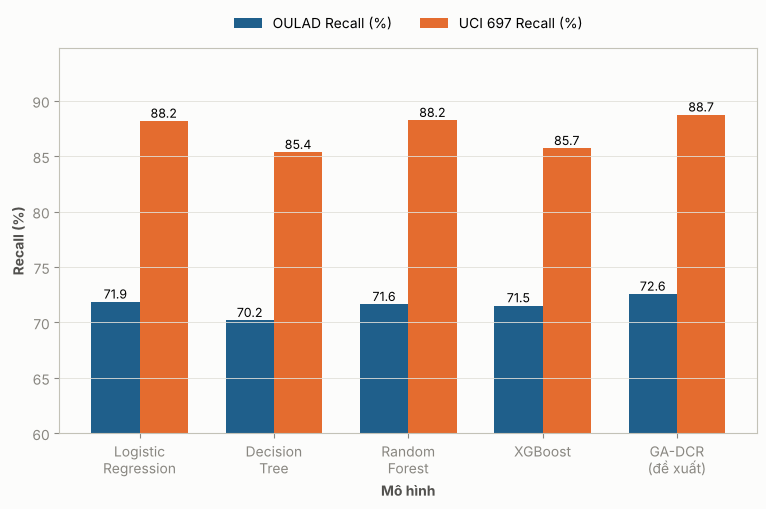

In [17]:
# Biểu đồ so sánh – mỗi mô hình 2 cột: OULAD và UCI 697
DS_COLORS = {"OULAD": "#1f5f8b", "UCI 697": "#e46c2f"}
XLAB = ["Logistic\nRegression", "Decision\nTree", "Random\nForest", "XGBoost", "GA-DCR\n(đề xuất)"]
def bar_compare(metric, ylabel, fname):
    d = RES.pivot(index="model", columns="dataset", values=metric).loc[MODELS] * 100
    x, w = np.arange(len(MODELS)), 0.36
    fig, ax = plt.subplots(figsize=(9, 5))
    for k, ds in enumerate(["OULAD", "UCI 697"]):
        bars = ax.bar(x + (k - .5) * w, d[ds], w, color=DS_COLORS[ds], label=f"{ds} {ylabel} (%)")
        for b, v in zip(bars, d[ds]): ax.text(b.get_x() + b.get_width() / 2, v + .3, f"{v:.1f}", ha="center", fontsize=9)
    lo = max(0, np.floor(d.values.min() / 10) * 10 - 10)
    ax.set_ylim(lo, min(100, d.values.max() + 6)); ax.set_xticks(x, XLAB, fontsize=10)
    ax.set_ylabel(f"{ylabel} (%)", fontweight="bold"); ax.set_xlabel("Mô hình", fontweight="bold")
    ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(.5, 1.12)); ax.grid(axis="x", visible=False)
    ax.spines["top"].set_visible(True); ax.spines["right"].set_visible(True)
    save_show(fig, fname)
bar_compare("recall", "Recall", "06_recall_comparison.png")

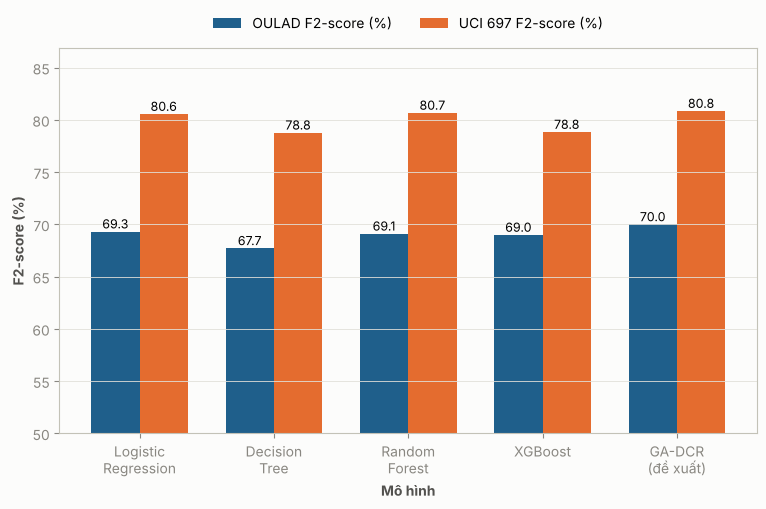

In [18]:
bar_compare("f2", "F2-score", "06_f2_comparison.png")

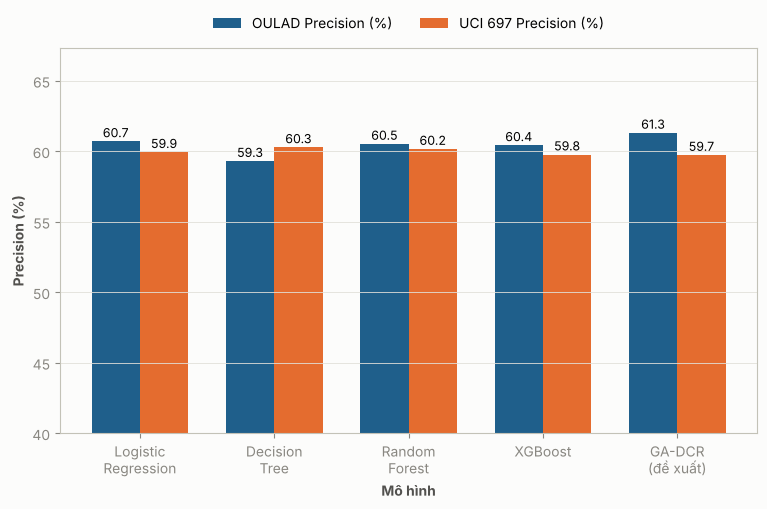

In [19]:
bar_compare("precision", "Precision", "06_precision_comparison.png")

### 6.1 Hệ số đóng góp của từng mô hình (tổng = 1)
OULAD dùng hệ số học trên train 2013. UCI 697 dùng trung bình hệ số của 5 fold.

**Lưu ý khi đọc hệ số UCI:** hệ số của Logistic Regression và Random Forest dao động khá mạnh giữa các fold (SD ≈ 0,3), nhưng **tổng của hai hệ số này ổn định** (khoảng 0,67). Lý do là trên UCI, hai mô hình này xếp hạng SV gần như giống nhau, nên GA có thể dồn trọng số cho bên này hay bên kia mà kết quả không đổi. Đây là hiện tượng bình thường khi các thành phần tương quan cao. Điều quan trọng là **cấu trúc**: phần lớn trọng số đặt vào các mô hình mạnh, các thành phần từ phân cụm luôn có đóng góp dương.

,OULAD,UCI 697,UCI 697 (SD giữa 5 fold)
LogReg,0.272,0.335,0.284
DecisionTree,0.083,0.096,0.077
RandomForest,0.121,0.333,0.300
XGBoost,0.239,0.088,0.071
XGB+Cluster,0.221,0.089,0.047
ClusterRisk,0.064,0.060,0.038
TỔNG,1.000,1.000,NaN


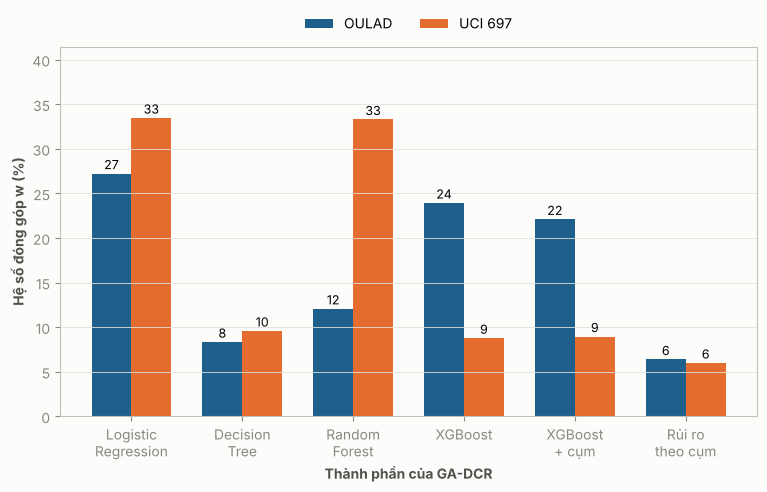

In [20]:
Wtab = pd.DataFrame({"OULAD": gw_o.w, "UCI 697": W_u.mean(0), "UCI 697 (SD giữa 5 fold)": W_u.std(0)}, index=COMPS)
Wtab.loc["TỔNG"] = [Wtab["OULAD"].sum(), Wtab["UCI 697"].sum(), np.nan]
save_tab(Wtab.round(3).reset_index(names="thanh_phan"), "06_ga_weights.csv"); display(Wtab.round(3))
LBL = ["Logistic\nRegression", "Decision\nTree", "Random\nForest", "XGBoost", "XGBoost\n+ cụm", "Rủi ro\ntheo cụm"]
x, w = np.arange(len(COMPS)), 0.36
fig, ax = plt.subplots(figsize=(9, 4.8))
for k, ds in enumerate(["OULAD", "UCI 697"]):
    vals = Wtab.loc[COMPS, ds].values * 100
    bars = ax.bar(x + (k - .5) * w, vals, w, color=DS_COLORS[ds], label=ds)
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + .5, f"{v:.0f}", ha="center", fontsize=9)
ax.set_xticks(x, LBL, fontsize=10); ax.set_ylabel("Hệ số đóng góp w (%)", fontweight="bold")
ax.set_xlabel("Thành phần của GA-DCR", fontweight="bold"); ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(.5, 1.12))
ax.set_ylim(0, max(Wtab.loc[COMPS, ["OULAD", "UCI 697"]].values.max() * 100 + 8, 30)); ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(True); ax.spines["right"].set_visible(True)
save_show(fig, "06_ga_weights.png")

### 6.2 Mức cảnh báo (phân cụm động)
Nếu phân cụm có ý nghĩa thì **tỷ lệ SV nguy cơ thật phải tăng dần** từ Xanh → Vàng → Cam → Đỏ.

,dataset,muc,ty_le_nguy_co_that,so_SV
0,OULAD,Cam,0.505,4192
1,OULAD,Vàng,0.320,8838
2,OULAD,Đỏ,0.872,1239
3,UCI 697,Cam,0.786,103
4,UCI 697,Vàng,0.326,1472
5,UCI 697,Xanh,0.084,2082
6,UCI 697,Đỏ,0.894,767


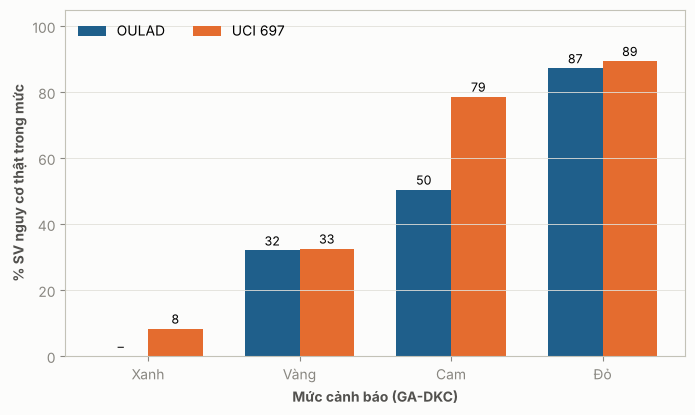

In [21]:
lv = pd.concat([pd.DataFrame({"muc": extra_o["level"], "at_risk": extra_o["y"], "dataset": "OULAD"}),
                pd.concat(lv_u).assign(dataset="UCI 697")])
lvtab = lv.groupby(["dataset", "muc"]).at_risk.agg(ty_le_nguy_co_that="mean", so_SV="size").reset_index()
save_tab(lvtab.round(3), "06_warning_levels.csv"); display(lvtab.round(3))
LV = ["Xanh", "Vàng", "Cam", "Đỏ"]; piv = lvtab.pivot(index="muc", columns="dataset", values="ty_le_nguy_co_that").reindex(LV) * 100
x, w = np.arange(len(LV)), 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, ds in enumerate(["OULAD", "UCI 697"]):
    vals = piv[ds].values; bars = ax.bar(x + (k - .5) * w, np.nan_to_num(vals), w, color=DS_COLORS[ds], label=ds)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, (0 if np.isnan(v) else v) + 1.5, "–" if np.isnan(v) else f"{v:.0f}", ha="center", fontsize=9)
ax.set_xticks(x, LV); ax.set_ylim(0, 105); ax.set_ylabel("% SV nguy cơ thật trong mức", fontweight="bold")
ax.set_xlabel("Mức cảnh báo (GA-DKC)", fontweight="bold"); ax.legend(ncol=2, loc="upper left"); ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(True); ax.spines["right"].set_visible(True)
save_show(fig, "06_risk_by_warning_level.png")

### 6.3 Vì sao tổ hợp tốt hơn và vì sao chỉ hơn một chút?
Bảng dưới là **tương quan thứ hạng (Spearman)** giữa điểm OOF của các thành phần trên OULAD. Tương quan **< 1** nghĩa là các mô hình **sai ở những SV khác nhau**. Khi đó trộn có trọng số sẽ bù trừ lỗi cho nhau, nên GA-DCR xếp hạng tốt hơn từng mô hình đơn.

In [22]:
C = pd.DataFrame({c: extra_o["OOF"][c] for c in COMPS}).corr(method="spearman")
save_tab(C.round(3).reset_index(names="thanh_phan"), "06_component_correlation.csv"); C.round(3)

,LogReg,DecisionTree,RandomForest,XGBoost,XGB+Cluster,ClusterRisk
LogReg,1.000,0.838,0.919,0.907,0.905,0.580
DecisionTree,0.838,1.000,0.877,0.849,0.847,0.535
RandomForest,0.919,0.877,1.000,0.946,0.945,0.601
XGBoost,0.907,0.849,0.946,1.000,0.977,0.556
XGB+Cluster,0.905,0.847,0.945,0.977,1.000,0.559
ClusterRisk,0.580,0.535,0.601,0.556,0.559,1.000


**Diễn giải kết quả (dùng cho phần thảo luận của bài báo):**
1. **Vì sao GA-DCR thắng?**
   - Các thành phần có tương quan cao nhưng chưa bằng 1, nên vẫn còn phần lỗi không trùng nhau để tổ hợp khai thác.
   - Hai thành phần từ phân cụm động đưa thêm thông tin về **nhóm hồ sơ hành vi**, thứ mà mô hình học từng SV riêng lẻ không thấy trực tiếp.
   - GA chọn hệ số **trực tiếp theo mục tiêu F2 có ràng buộc**, đúng tiêu chí của bài toán, thay vì theo log-loss hay accuracy.
2. **Vì sao mức hơn chỉ khoảng 0,5–1 điểm %?**
   - (i) 4 mô hình học **cùng một bộ đặc trưng**, nên tương quan giữa chúng cao, khoảng 0,8–0,95.
   - (ii) Ở mốc **ngày 28**, lượng thông tin về SV còn ít; trần dự báo bị giới hạn bởi dữ liệu chứ không bởi thuật toán.
   - (iii) Đánh giá chặt: **chia theo thời gian, loại SV trùng, ngưỡng chọn trên train**. Các kết quả 96–99% trong một số bài báo thường đến từ chia ngẫu nhiên hoặc dùng điểm cuối kỳ (rò rỉ dữ liệu).
3. **Vì sao Precision của UCI có thể thấp hơn baseline một chút?** F2 coi Recall nặng gấp đôi, nên GA chấp nhận đổi một phần nhỏ Precision để bắt thêm SV nguy cơ. Precision vẫn luôn ≥ $P_{min}$ trên train và ổn định giữa các fold (xem cột SD).
4. **Không có tinh chỉnh riêng cho mô hình đề xuất:** các thành phần dùng đúng siêu tham số của baseline, nên phần cải thiện đến từ phương pháp kết hợp.

---
## §7. Điểm mới so với bài báo tham khảo (Wang, 2025 – *Scientific Reports* 15:35122)
| Khía cạnh | Bài báo tham khảo (Hybrid-AIPM) | Đề tài này (GA-DCR) |
|---|---|---|
| Thuật toán cơ sở | DT, RF, **SVM, ANN** | **LR, DT, RF, XGBoost**, cộng 2 thành phần từ phân cụm động |
| Cách kết hợp | Soft-voting (trọng số bằng nhau) hoặc stacking | **Tổ hợp lồi $R=\sum_m w_m r_m$, $\sum w_m=1$**, hệ số do **GA huấn luyện theo F2 có ràng buộc** |
| Chuẩn hóa đầu ra | Cộng trực tiếp xác suất | **Chuẩn hóa thứ hạng** trước khi trộn, vì xác suất của các mô hình khác thang đo |
| Phân cụm | Chỉ nhắc K-means trong phần tổng quan | **GA-DKC:** GA tối ưu *k* và trọng số đặc trưng; sinh mức cảnh báo; chạy theo thời gian |
| Chỉ số tối ưu | **Accuracy** | **Recall và F2**, Precision là ràng buộc |
| Quy tắc cảnh báo | Ngưỡng 0,5 | **Top-q% theo năng lực tư vấn**, q chọn trên train |
| Chia dữ liệu | Stratified 10-fold ngẫu nhiên | **OULAD theo thời gian** (2013 → 2014), loại SV trùng; UCI 5-fold phân tầng |
| Đầu ra | Nhãn rủi ro | Điểm rủi ro, **mức Xanh/Vàng/Cam/Đỏ**, **hệ số đóng góp** từng mô hình |

**Đóng góp chính:**
1. **GA-DKC:** phân cụm động có hướng dẫn rủi ro, tự sinh mức cảnh báo.
2. **GA-DCR:** tổ hợp lồi của 4 mô hình cơ sở và 2 thành phần cụm, với hệ số huấn luyện bằng GA theo F2 có ràng buộc Precision, trên điểm đã chuẩn hóa thứ hạng.
3. **Giao thức đánh giá chống rò rỉ**, theo thời gian, với quy tắc cảnh báo top-q% bền với thay đổi giữa các khóa.

### Kết luận tuần 2
- **Đặc trưng:** khung 6 nhóm G1–G6 dùng chung cho cả OULAD và UCI 697 (§3).
- **GA-DCR** là tổ hợp có trọng số (tổng = 1) của 6 thành phần, hệ số học bằng GA. Kết quả so với baseline tốt nhất nằm ở bảng chênh lệch (§6) và 3 biểu đồ Recall, F2, Precision.
- **Mức cảnh báo** từ phân cụm động có tỷ lệ nguy cơ thật tăng dần từ Xanh đến Đỏ (§6.2).
- **Hướng tuần 3:**
  1. Kiểm định thống kê McNemar và bootstrap cho chênh lệch;
  2. Đặc trưng quỹ đạo mức cảnh báo qua các mốc;
  3. Thêm thành phần đa dạng hơn (ví dụ mô hình chuỗi thời gian) để giảm tương quan giữa các thành phần.